# Rise to 12 Inches vs. Peak Depth
## FloodNet NYC Tutorial
Author: Mark Bauer

# Summary

During a cloudburst, water can climb to a foot deep on a street in a couple of minutes. This notebook looks at that steepness, the **rate of rise**, and asks one plain question: when the water rises faster, does it also end up **deeper**?

We can't see the rain in these datasets, only the water the sensors recorded: a one-minute record of how deep it got at each sensor. So everything here describes what happened **at the sensor**. Rate of rise reflects the storm, but also the site: how the street is shaped, where the sensor sits, and how quickly water collects there. We can't separate those without rainfall data, and the notebook says where that limits us.

As in [05-temporal-patterns.ipynb](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/05-temporal-patterns.ipynb), we keep **tidal** and **non-tidal** sensors apart, because they flood in different ways and rise at very different speeds.

1. **Setup**: load the data and build a "time to 12 inches" table
2. **Two Ways to a Foot of Water**: one non-tidal event and one tidal event, side by side
3. **How Fast, and How Deep**: the two variables for every event
4. **Does a Faster Rise Mean a Deeper Flood?**: the correlation, and two checks on it
5. **Takeaways and Limitations**

### A few terms, in plain words

- **Peak depth**: the deepest the water got during one flood event, in inches.
- **Rate of rise**: how fast the water climbed, in inches per minute. A big number means a sudden, flash-flood-like rise.
- **Tidal vs. non-tidal sensors**: the metadata marks some sensors as `tidally_influenced`, meaning their water levels are affected by nearby tides. Non-tidal sensors flood mostly from rain. The flag describes the *sensor*, not each flood, so a tidal sensor can still record a flood caused by rain.
- **Log scale**: when a few values are huge and most are small (as with our rise times), we space the axis by multiples (1, 10, 100) so the small values don't get squashed against the edge.
- **Rank correlation**: one number from -1 to +1 that says whether "faster rise" tends to go with "deeper peak", without assuming the relationship is a straight line.

# Import Libraries

In [1]:
# libraries
# Standard library
from datetime import date

# Third-party
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from mpl_toolkits.axes_grid1 import make_axes_locatable

import floodnet

# series colors, matching 05-temporal-patterns.ipynb
colors = floodnet.COLORBLIND_PALETTE
TIDAL_COLOR = colors[4]      # cyan
NON_TIDAL_COLOR = colors[0]  # blue

# 1) Setup

We load the two datasets, join them on `sensor_id`, convert the UTC timestamps to
New York local time, and decode the per-event depth/time profiles from JSON into
list columns — the same preparation used in the earlier notebooks.

In [2]:
# read the two datasets and join them on sensor_id
metadata_df = pl.read_csv("data/sensor-metadata.csv", try_parse_dates=True)
events_df = pl.read_csv(
    "data/flood-events.csv",
    infer_schema_length=100000,  # sparse columns need a deep scan to type correctly
    try_parse_dates=True,
)
merged_df = events_df.join(
    metadata_df.drop("sensor_name"),
    on="sensor_id",
    how="left",  # keep all events, even if metadata is missing
)

# timestamps are UTC; convert to NYC local time (handles daylight saving)
merged_df = merged_df.with_columns(
    pl.col("flood_start_time")
        .dt.replace_time_zone("UTC")
        .dt.convert_time_zone("America/New_York")
        .alias("flood_start_time_et"),
    pl.col("flood_end_time")
        .dt.replace_time_zone("UTC")
        .dt.convert_time_zone("America/New_York")
        .alias("flood_end_time_et"),
)

# the per-event depth/time profiles arrive as JSON strings; decode to list columns
merged_df = merged_df.with_columns(
    pl.col("flood_profile_time_secs").str.json_decode(pl.List(pl.Float64)),
    pl.col("flood_profile_depth_inches").str.json_decode(pl.List(pl.Float64)),
)

print(f"Flood events: {merged_df.height:,}")
print(f"Sensors:      {metadata_df.height:,}")
merged_df.select(
    ["sensor_name", "flood_start_time_et", "max_depth_inches",
     "tidally_influenced", "borough"]
).head()

Flood events: 3,422
Sensors:      491


sensor_name,flood_start_time_et,max_depth_inches,tidally_influenced,borough
str,"datetime[μs, America/New_York]",f64,str,str
"""Q - Beach 84 St""",2023-10-30 08:00:39 EDT,17.72,"""Yes""","""Queens"""
"""BX - 1st St/Avenue A""",2025-04-26 19:17:20 EDT,6.18,"""No""","""Bronx"""
"""Q - Beach 35 St/Beach Channel …",2024-02-09 06:41:01 EST,5.31,"""Yes""","""Queens"""
"""BX - Tibbett Ave/W 234th St""",2025-08-20 17:05:19 EDT,1.18,"""No""","""Bronx"""
"""Q - Davenport Ct 1""",2024-01-09 19:39:25 EST,2.09,"""Yes""","""Queens"""


## How often does flooding reach 12 inches?

Twelve inches, a foot of water, is not an arbitrary line. It is one of the depths the dataset itself reports (the `duration_above_12_inches_mins` column), and it is the severe-flooding threshold used in [05-temporal-patterns.ipynb](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/05-temporal-patterns.ipynb). The cell below shows what share of flood events get there, for tidal and non-tidal sensors separately.

In [3]:
SEVERE_THRESHOLD_IN = 12  # the dataset's own severe-depth flag

reach_summary = (
    merged_df.group_by("tidally_influenced")
    .agg(
        pl.len().alias("events"),
        (pl.col("max_depth_inches") >= SEVERE_THRESHOLD_IN).sum().alias("reached_12in"),
    )
    .with_columns(
        (pl.col("reached_12in") / pl.col("events") * 100).round(1).alias("pct_reaching_12in")
    )
    .sort("events", descending=True)
)

total = merged_df.height
reached = merged_df.filter(pl.col("max_depth_inches") >= SEVERE_THRESHOLD_IN).height
print(f"Of {total:,} flood events, {reached:,} ({reached / total * 100:.1f}%) "
      f"reached {SEVERE_THRESHOLD_IN} inches.")
reach_summary

Of 3,422 flood events, 288 (8.4%) reached 12 inches.


tidally_influenced,events,reached_12in,pct_reaching_12in
str,u32,u32,f64
"""Yes""",2285,204,8.9
"""No""",1137,84,7.4


## Building the "time to 12 inches" table

For every event that reaches 12 inches, `floodnet.time_to_threshold` (introduced in [03-flood-profiles.ipynb](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/03-flood-profiles.ipynb)) finds the first time the water **rises through** 12 inches and interpolates between the two one-minute readings on either side, so the timing isn't rounded to the sampling interval. It also returns the average **rate of rise** to that depth (`rate_to_thresh_in_per_min`). We carry `sensor_id` through so we can attach each sensor's name and tidal status on a stable key.

An event whose record *starts* above 12 inches never rises through the line, so it has no time to 12 inches and drops out. The cell below counts those.

In [4]:
# one row per event that reaches 12 in.; top_n defaults to 10, so pass the row
# count to keep every qualifying event rather than only the fastest few
crossings_df = floodnet.time_to_threshold(
    df=merged_df,
    threshold_inches=SEVERE_THRESHOLD_IN,
    top_n=merged_df.height,
    name_col="sensor_id",  # stable key to join on below
)

crossings_df = (
    crossings_df.join(
        metadata_df.select(["sensor_id", "sensor_name", "tidally_influenced", "borough"]),
        left_on="name",
        right_on="sensor_id",
        how="left",
    )
    .rename({"name": "sensor_id", "depth_max_inches": "max_depth_inches"})
)

print(f"Events reaching {SEVERE_THRESHOLD_IN} in.:                {reached}")
print(f"Events with a time to {SEVERE_THRESHOLD_IN} in.:          {crossings_df.height}")
print(f"Dropped (record starts above {SEVERE_THRESHOLD_IN} in.):  {reached - crossings_df.height}")
crossings_df.select(
    ["sensor_name", "tidally_influenced", "borough",
     "time_to_thresh_minutes", "rate_to_thresh_in_per_min", "max_depth_inches"]
).head()

Events reaching 12 in.:                288
Events with a time to 12 in.:          287
Dropped (record starts above 12 in.):  1


sensor_name,tidally_influenced,borough,time_to_thresh_minutes,rate_to_thresh_in_per_min,max_depth_inches
str,str,str,f64,f64,f64
"""M - Rivington St/Suffolk St""","""No""","""Manhattan""",2.05,5.84,18.5
"""BK - Carroll St/4th Av""","""No""","""Brooklyn""",2.28,5.26,31.3
"""BK - Carroll St/4th Av""","""No""","""Brooklyn""",2.53,4.75,28.15
"""BK - Carroll St/4th Av""","""No""","""Brooklyn""",2.92,4.11,35.94
"""Q - 204th St/ 100th Ave""","""No""","""Queens""",2.93,4.1,32.72


# 2) Two Ways to a Foot of Water

Before any statistics, look at two real events. Both reach the same foot of water (the dashed line). One is at a **non-tidal** sensor: Carroll St / 4th Ave in Gowanus, Brooklyn, during Tropical Storm Ophelia on September 29, 2023, the storm featured in [03-flood-profiles.ipynb](https://github.com/mebauer/floodnet-nyc-tutorial/blob/main/03-flood-profiles.ipynb). The other is a typical event at a **tidal** sensor: the one with the median time to 12 inches.

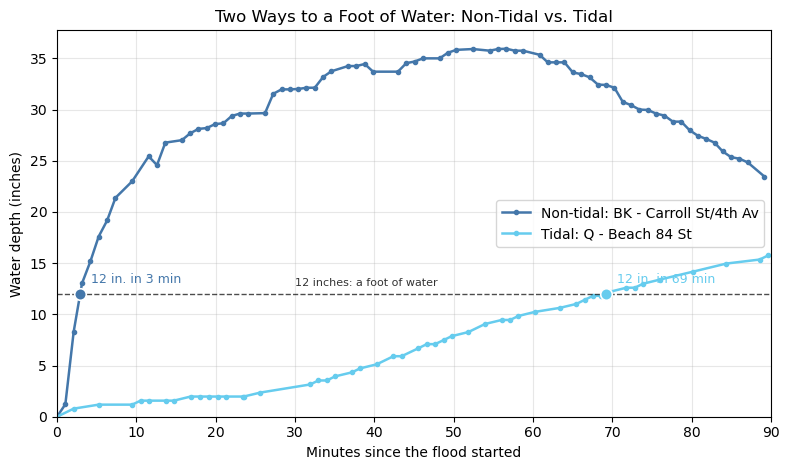

In [5]:
# A rain event: Carroll St / 4th Ave (Gowanus) during Tropical Storm Ophelia.
# The date is historical, so this selection is stable across data refreshes.
non_tidal_event = (
    crossings_df
    .filter(
        (pl.col("sensor_name") == "BK - Carroll St/4th Av")
        & (pl.col("start").dt.date() == date(2023, 9, 29))
    )
    .sort("max_depth_inches", descending=True)
    .row(0, named=True)
)

# A typical tidal event: the median time to 12 in. among tidal sensors.
tidal_sorted = crossings_df.filter(pl.col("tidally_influenced") == "Yes").sort(
    "time_to_thresh_minutes"
)
tidal_event = tidal_sorted.row(tidal_sorted.height // 2, named=True)

WINDOW_MIN = 90  # minutes of each event to show

fig, ax = plt.subplots(figsize=(8, 4.8))
for event, color, kind in [
    (non_tidal_event, NON_TIDAL_COLOR, "Non-tidal"),
    (tidal_event, TIDAL_COLOR, "Tidal"),
]:
    t = np.array(event["x_values"]) / 60          # seconds -> minutes
    d = np.array(event["y_values"])
    keep = t <= WINDOW_MIN
    ax.plot(t[keep], d[keep], color=color, marker="o", ms=3, lw=1.8,
            label=f"{kind}: {event['sensor_name']}")
    # mark where this event crosses 12 inches
    tc = event["time_to_thresh_minutes"]
    ax.scatter([tc], [SEVERE_THRESHOLD_IN], color=color, s=70, zorder=5,
               edgecolor="white", linewidth=1.2)
    ax.annotate(f"12 in. in {round(tc)} min", (tc, SEVERE_THRESHOLD_IN),
                textcoords="offset points", xytext=(8, 8), fontsize=9, color=color)

ax.axhline(SEVERE_THRESHOLD_IN, color="black", ls="--", lw=1, alpha=0.7)
# caption sits in the open gap between the two curves, clear of both annotations
ax.text(30, SEVERE_THRESHOLD_IN + 0.6, "12 inches: a foot of water",
        ha="left", va="bottom", fontsize=8, color="black", alpha=0.8)
ax.set_xlim(0, WINDOW_MIN)
ax.set_ylim(bottom=0)
ax.set_xlabel("Minutes since the flood started")
ax.set_ylabel("Water depth (inches)")
ax.set_title("Two Ways to a Foot of Water: Non-Tidal vs. Tidal")
ax.legend(loc="center right")
ax.grid(True, alpha=0.3)
fig.tight_layout()

Both lines reach the same foot of water. Compare the two annotated times to get there. For scale, the National Weather Service's *Turn Around, Don't Drown* guidance notes that six inches of **moving** water can knock an adult off their feet, and twelve inches of moving water can carry away many cars.

The rest of the notebook measures how common each kind of rise is, and whether a faster rise tends to end in a deeper flood.

# 3) How Fast, and How Deep

Both quantities are strongly right-skewed, the usual shape for hydrologic data, so we read the **median** rather than the mean, and we put the rise time on a log scale. We summarize tidal and non-tidal sensors separately.

In [6]:
rate_summary = (
    crossings_df.group_by("tidally_influenced")
    .agg(
        pl.len().alias("events"),
        pl.col("time_to_thresh_minutes").median().round(1).alias("median_time_min"),
        pl.col("rate_to_thresh_in_per_min").median().round(2).alias("median_rate_in_per_min"),
        pl.col("max_depth_inches").median().round(1).alias("median_peak_in"),
    )
    .sort("events", descending=True)
)
rate_summary

tidally_influenced,events,median_time_min,median_rate_in_per_min,median_peak_in
str,u32,f64,f64,f64
"""Yes""",203,69.1,0.17,15.6
"""No""",84,10.5,1.14,19.9


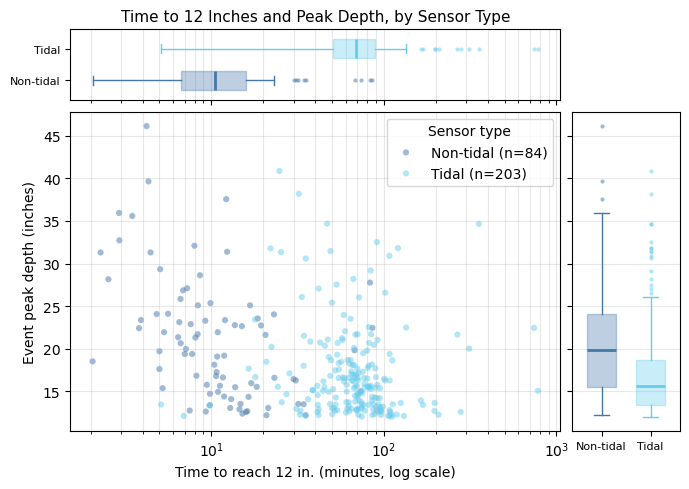

In [7]:
time_min = crossings_df["time_to_thresh_minutes"].to_numpy()
peak_in = crossings_df["max_depth_inches"].to_numpy()
tid = crossings_df["tidally_influenced"].to_numpy()

groups = ["No", "Yes"]
group_color = {"No": NON_TIDAL_COLOR, "Yes": TIDAL_COLOR}
group_label = {"No": "Non-tidal", "Yes": "Tidal"}

fig, ax = plt.subplots(figsize=(7, 5))
for group in groups:
    mask = tid == group
    ax.scatter(time_min[mask], peak_in[mask], s=20, alpha=0.5,
               color=group_color[group], edgecolor="none",
               label=f"{group_label[group]} (n={int(mask.sum())})")
ax.set_xscale("log")
ax.set_xlabel("Time to reach 12 in. (minutes, log scale)")
ax.set_ylabel("Event peak depth (inches)")
ax.legend(title="Sensor type", loc="upper right")
ax.grid(True, which="both", alpha=0.3)

# box-and-whisker plots (median, IQR, whiskers) on each margin
divider = make_axes_locatable(ax)
ax_top = divider.append_axes("top", size="22%", pad=0.12, sharex=ax)
ax_right = divider.append_axes("right", size="22%", pad=0.12, sharey=ax)


def _style_box(bp, color):
    for patch in bp["boxes"]:
        patch.set(facecolor=color, alpha=0.35, edgecolor=color)
    for element in ("whiskers", "caps"):
        for line in bp[element]:
            line.set(color=color)
    for median in bp["medians"]:
        median.set(color=color, linewidth=2)
    for flier in bp["fliers"]:
        flier.set(marker="o", markersize=3, markerfacecolor=color,
                  markeredgecolor="none", alpha=0.5)


for i, group in enumerate(groups):
    bp = ax_top.boxplot(time_min[tid == group], positions=[i], orientation="horizontal",
                        widths=0.6, patch_artist=True, manage_ticks=False)
    _style_box(bp, group_color[group])
ax_top.set_yticks(range(len(groups)))
ax_top.set_yticklabels([group_label[g] for g in groups], fontsize=8)
ax_top.tick_params(axis="x", labelbottom=False)
ax_top.set_ylim(-0.6, len(groups) - 0.4)
ax_top.grid(True, axis="x", which="both", alpha=0.3)

for i, group in enumerate(groups):
    bp = ax_right.boxplot(peak_in[tid == group], positions=[i], orientation="vertical",
                          widths=0.6, patch_artist=True, manage_ticks=False)
    _style_box(bp, group_color[group])
ax_right.set_xticks(range(len(groups)))
ax_right.set_xticklabels([group_label[g] for g in groups], fontsize=8)
ax_right.tick_params(axis="y", labelleft=False)
ax_right.set_xlim(-0.6, len(groups) - 0.4)
ax_right.grid(True, axis="y", alpha=0.3)

ax_top.set_title("Time to 12 Inches and Peak Depth, by Sensor Type", fontsize=11, pad=6)
fig.tight_layout()

We'd expect non-tidal sensors to rise faster: rain on pavement can collect at a low spot in minutes, while a tide rises over hours. The medians table and the top box plots show how far apart the two groups actually are in time to 12 inches, and the right-hand box plots compare their peaks. It's the same comparison as the two events in Section 2, now for every event at once.

**What not to do:** pool the two groups into one "all sensors" summary. Whichever group has more events would dominate a pooled median, which would then mostly describe that kind of flooding.

**Keep in mind:** peak depth is measured at the sensor, and sensors sit at different heights above their local low point (`lowest_point_height_delta_inches`). Comparing raw depths *across* sensors partly compares where the sensors were mounted.

# 4) Does a Faster Rise Mean a Deeper Flood?

In the figure above, do faster rises (further left on the time axis) tend to sit higher? Let's put a number on it, for each sensor type separately.

A **Pearson** correlation measures a *straight-line* fit, and on data this skewed it gets pulled around by a few very slow events. **Spearman** compares *ranks* instead, so it catches "faster tends to go with deeper" without assuming a straight line. For skewed hydrologic data, the rank measure is usually the safer choice.

In [8]:
def corrs(df):
    return df.select(
        time_vs_depth_pearson=pl.corr("time_to_thresh_minutes", "max_depth_inches", method="pearson"),
        time_vs_depth_spearman=pl.corr("time_to_thresh_minutes", "max_depth_inches", method="spearman"),
        rate_vs_depth_spearman=pl.corr("rate_to_thresh_in_per_min", "max_depth_inches", method="spearman"),
    )

rows = []
for group in groups:
    sub = crossings_df.filter(pl.col("tidally_influenced") == group)
    c = corrs(sub)
    rows.append({
        "sensor type": group_label[group],
        "n": sub.height,
        "time~depth (Pearson)": round(c["time_vs_depth_pearson"][0], 3),
        "time~depth (Spearman)": round(c["time_vs_depth_spearman"][0], 3),
        "rate~depth (Spearman)": round(c["rate_vs_depth_spearman"][0], 3),
    })

pl.DataFrame(rows)

sensor type,n,time~depth (Pearson),time~depth (Spearman),rate~depth (Spearman)
str,i64,f64,f64,f64
"""Non-tidal""",84,-0.203,-0.492,0.491
"""Tidal""",203,0.009,-0.182,0.18


Compare the Pearson and Spearman columns: where they disagree, the skew is pulling Pearson around. `rate~depth` is the mirror of `time~depth` (a faster rate means less time), so they carry the same information with opposite signs. A positive `rate~depth` means faster rises tend to go with deeper peaks.

It's tempting to stop here and read a positive number as "faster-rising floods peak deeper". Before we do, two checks on how this number was built.

## Check 1: Measuring the Rise Away from the Peak

A flood's rise slows down as it approaches its peak. That builds part of this correlation into the measurement. An event that peaks at 12.5 inches is still crawling toward its crest when it crosses 12 inches, so its average rise *to 12 inches* is slow almost by definition. An event that peaks at 30 inches crosses 12 inches on the steep part of its rise.

To avoid that, we measure the rise to **4 inches** instead (the dataset's other depth threshold), for the same non-tidal events. Four inches is well below every one of these peaks.

In [9]:
non_tidal_crossings_df = crossings_df.filter(pl.col("tidally_influenced") == "No")

# same events (non-tidal, peak >= 12 in.), but time the rise to 4 in. instead
rise_to_4in_df = floodnet.time_to_threshold(
    df=merged_df.filter(
        (pl.col("tidally_influenced") == "No")
        & (pl.col("max_depth_inches") >= SEVERE_THRESHOLD_IN)
    ),
    threshold_inches=4,
    top_n=merged_df.height,
    name_col="sensor_id",
)

rate_to_12 = non_tidal_crossings_df.select(
    pl.corr("rate_to_thresh_in_per_min", "max_depth_inches", method="spearman")
).item()
rate_to_4 = rise_to_4in_df.select(
    pl.corr("rate_to_thresh_in_per_min", "depth_max_inches", method="spearman")
).item()

print(f"Non-tidal events: {non_tidal_crossings_df.height} (to 12 in.), {rise_to_4in_df.height} (to 4 in.)")
print(f"Spearman, rate of rise to 12 in. vs. peak depth: {rate_to_12:.2f}")
print(f"Spearman, rate of rise to 4 in.  vs. peak depth: {rate_to_4:.2f}")
print(f"Change from measuring the rise away from the crest: {rate_to_4 - rate_to_12:+.2f}")

Non-tidal events: 84 (to 12 in.), 84 (to 4 in.)
Spearman, rate of rise to 12 in. vs. peak depth: 0.49
Spearman, rate of rise to 4 in.  vs. peak depth: 0.22
Change from measuring the rise away from the crest: -0.27


Compare the two numbers. These are the same events, so any difference between them comes from *where* we measured the rise, not from the floods themselves. The more the correlation drops when we measure on the steep, early part of the rise, the more of the original number was built in by the measurement.

## Check 2: Is It the Storm or the Site?

The non-tidal events are not independent of each other. A few sensors appear again and again, and every sensor has its own street shape and mounting height. If some sites simply fill fast *and* deep, a pooled correlation would pick that up even if, at any one site, a faster storm didn't produce a deeper flood.

We look at this two ways:

- **Between sites:** one row per sensor (its median rate and median peak).
- **Within sites:** for sensors with at least 3 events, compare each event with that sensor's own average. Did the faster-than-usual floods at a site also peak deeper than usual there?

In [10]:
MIN_EVENTS_PER_SENSOR = 3

events_per_sensor = non_tidal_crossings_df.group_by("sensor_id").agg(pl.len().alias("events"))
repeat_sensors = events_per_sensor.filter(pl.col("events") >= MIN_EVENTS_PER_SENSOR).height

print(f"Non-tidal events: {non_tidal_crossings_df.height}, "
      f"from {events_per_sensor.height} sensors")
print(f"Sensors with at least {MIN_EVENTS_PER_SENSOR} events: {repeat_sensors}")
display(
    non_tidal_crossings_df.group_by("sensor_name").agg(pl.len().alias("events"))
    .sort("events", descending=True).head(5)
)

# between sites: one row per sensor
by_sensor_df = non_tidal_crossings_df.group_by("sensor_id").agg(
    pl.col("rate_to_thresh_in_per_min").median(),
    pl.col("max_depth_inches").median(),
)
between = by_sensor_df.select(
    pl.corr("rate_to_thresh_in_per_min", "max_depth_inches", method="spearman")
).item()

# within sites: each event compared with its own sensor's average
# (rate on a log scale, since it is so skewed)
within_df = (
    non_tidal_crossings_df
    .filter(pl.len().over("sensor_id") >= MIN_EVENTS_PER_SENSOR)
    .with_columns(pl.col("rate_to_thresh_in_per_min").log10().alias("log_rate"))
    .with_columns(
        (pl.col("log_rate") - pl.col("log_rate").mean().over("sensor_id")).alias("rate_vs_usual"),
        (pl.col("max_depth_inches") - pl.col("max_depth_inches").mean().over("sensor_id")).alias("depth_vs_usual"),
    )
)
within = within_df.select(pl.corr("rate_vs_usual", "depth_vs_usual", method="spearman")).item()

print(f"All events:    Spearman {rate_to_12:.2f} across {non_tidal_crossings_df.height} events")
print(f"Between sites: Spearman {between:.2f} across {by_sensor_df.height} sensors")
print(f"Within sites:  Spearman {within:.2f} across {within_df.height} events "
      f"at {within_df['sensor_id'].n_unique()} sensors")

Non-tidal events: 84, from 47 sensors
Sensors with at least 3 events: 8


sensor_name,events
str,u32
"""BK - Carroll St/4th Av""",8
"""BK - 9th St/Smith St""",6
"""BK - Wallabout St/Throop Ave""",4
"""Q - 204th St/ 100th Ave""",3
"""Q - Liberty Ave/ 183rd St""",3


All events:    Spearman 0.49 across 84 events
Between sites: Spearman 0.52 across 47 sensors
Within sites:  Spearman 0.33 across 31 events at 8 sensors


How to read these:

- **Start with the sample sizes.** The within-site number only uses sensors with repeat events at this depth. If there are only a handful, that number rests on very few events and is too uncertain to lean on. Try changing `MIN_EVENTS_PER_SENSOR` to 2 or 4 and watch how much it moves.
- **Compare between-site with all events.** If the between-site correlation is about as strong as the pooled one, much of the pattern is about *which sites* flood fast and deep, which depends on street shape and sensor placement as much as on the storm.

**Decision:** treat the pooled correlation as an upper bound, not a finding. It includes the crest effect from Check 1 and the differences between sites from Check 2. Only a within-site number, measured away from the crest, speaks to whether a faster storm produces a deeper flood at the same street, and with few repeat events per sensor that number is very uncertain. Answering the question properly needs rainfall data and more repeat events per sensor. The comparison that is grounded in physics, and does not depend on this correlation, is the one in Section 3: how differently tidal and non-tidal sensors rise.

# 5) Takeaways and Limitations

**What this notebook shows you how to check**

- How rare severe flooding is, by sensor type (Section 1).
- How differently tidal and non-tidal sensors rise to a foot of water (Section 3). Expect rain-driven flooding to rise faster than tidal flooding, and check the medians each time the data is refreshed.
- How fast the steepest rises are: some non-tidal sites can go from dry to a foot of water in minutes, as the Gowanus event in Section 2 shows.
- How to test a correlation on skewed data: use a rank-based measure, then check how the number was built (Section 4).

**What this data can't tell us**

- Whether a faster storm produces a deeper flood at the same street. Rate of rise and peak depth both depend on the site, and the pooled correlation includes a measurement effect near the crest (Section 4).
- Rankings of sites or neighborhoods by how dangerous they are. Rates of rise and depths are observed at each sensor, and depend on which storms hit it and where it was mounted.

**Limitations**

- *No rainfall.* We see the water at the sensor, not the rain that caused it, so we can't tell a fast rise caused by intense rain from one caused by the shape of the site.
- *Selection.* Everything here is about events that reached 12 inches. It says nothing about the many shallower ones.
- *Measured vs. local low point.* Sensors are usually mounted above the lowest point nearby (`lowest_point_height_delta_inches`), so water at the low point is deeper than what the sensor records. We used the measured depth throughout. Because that offset differs from sensor to sensor, correcting for it could change comparisons *between* sensors, though not the order of events at one sensor.
- *Threshold choice.* Twelve inches is the dataset's own severe-depth threshold and is defensible, but it is a choice; 4 or 24 inches would select different events.